In [1]:
library(dplyr)
library(Seurat)
library(patchwork)
library(ggplot2)
library(sctransform)
# library(glmGamPoi)
# library(cluster)
# library(Matrix)
# library(fitdistrplus)
# library(stats)
# library(cgwtools)
# library(stringr)
# library(SeuratDisk)
# library(limma)
# library(RColorBrewer)
# library(DESeq2)
# library(MAST)
# library(rlist)
# library(EnhancedVolcano)

#use .udunits-2.2.28


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


The legacy packages maptools, rgdal, and rgeos, underpinning this package
will retire shortly. Please refer to R-spatial evolution reports on
https://r-spatial.org/r/2023/05/15/evolution4.html for details.
This package is now running under evolution status 0 

Attaching SeuratObject



# New Script

In [2]:
library(Seurat)

process_lane <- function(lane_number) {
  # Construct the file path based on the lane number
  file_path <- paste0("/Genomics/pritykinlab/share/perturbseq/fromMarc/new_data/exp49_CP8_old/cellranger/lane", lane_number, "/filtered_feature_bc_matrix.h5")
  
  # Load Lane data
  lane_data <- Read10X_h5(file_path)
  
  # Create Seurat object for the lane
  lane <- CreateSeuratObject(counts = lane_data[["Gene Expression"]], min.cells = 10, min.features = 400, project = paste0("lane", lane_number))
  lane[["gRNA"]] <- CreateAssayObject(lane_data[["CRISPR Guide Capture"]][, colnames(x = lane)], min.cells = 5)
  lane.hto <- lane_data[["Antibody Capture"]]
  
  if (lane_number <= 4) {
    hashtags_to_keep <- c("Hashtag1", "Hashtag2", "Hashtag3", "Hashtag4", "Hashtag5", "Hashtag6", "Hashtag7")
  } else {
    hashtags_to_keep <- c("Hashtag1", "Hashtag2", "Hashtag3", "Hashtag4", "Hashtag5", "Hashtag6", "Hashtag7", "Hashtag8")
  }
  lane.hto <- lane.hto[which(rownames(lane.hto) %in% hashtags_to_keep),]
  
  # Add the filtered HTO data to the Seurat object
  lane[["HTO"]] <- CreateAssayObject(lane.hto[, colnames(x = lane)], min.cells = 5)
  
  # Extract the "Antibody Capture" assay data
  hto_matrix <- GetAssayData(lane, assay = "HTO", slot = "counts")
  
  # Calculate the total count of each hashtag across cells
  total_counts_per_hashtag <- rowSums(hto_matrix)
  
  # Normalize HTO data
  lane <- NormalizeData(lane, assay = "HTO", normalization.method = "CLR", margin = 2, verbose = FALSE)
  
  # Run HTODemux
  lane <- HTODemux(lane, assay = "HTO", positive.quantile = 0.99)
  
  # Return the total counts and the processed Seurat object
  list(total_counts_per_hashtag = total_counts_per_hashtag, lane = lane)
}

# Process all lanes from 1 to 16
results <- lapply(1:8, process_lane)

Genome matrix has multiple modalities, returning a list of matrices for this genome

Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Cutoff for Hashtag1 : 5 reads

Cutoff for Hashtag2 : 23 reads

Cutoff for Hashtag3 : 20 reads

Cutoff for Hashtag4 : 63 reads

Cutoff for Hashtag5 : 32 reads

Cutoff for Hashtag6 : 38 reads

Cutoff for Hashtag7 : 140 reads

Genome matrix has multiple modalities, returning a list of matrices for this genome

Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Cutoff for Hashtag1 : 4 reads

Cutoff for Hashtag2 : 26 reads

Cutoff for Hashtag3 : 20 reads

Cutoff for Hashtag4 : 21 reads

Cutoff for Hashtag5 : 29 reads

Cutoff for Hashtag6 : 35 reads

Cutoff for Hashtag7 : 36 reads

Genome matrix has multiple modalities, returning a list of matrices for this genome

Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”
Cutoff for Hashtag1 : 

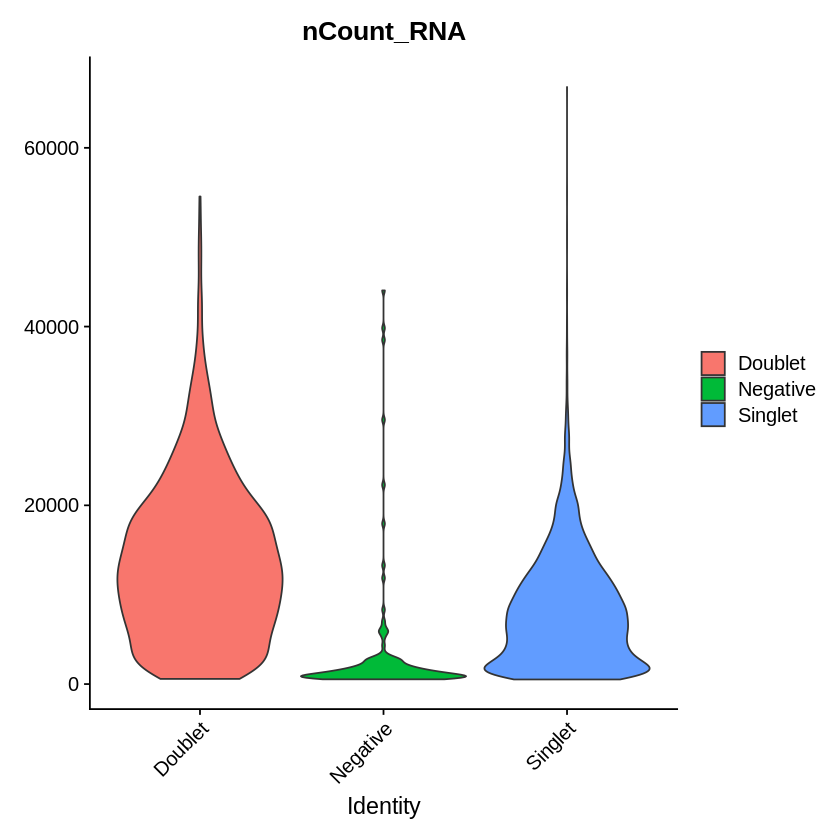

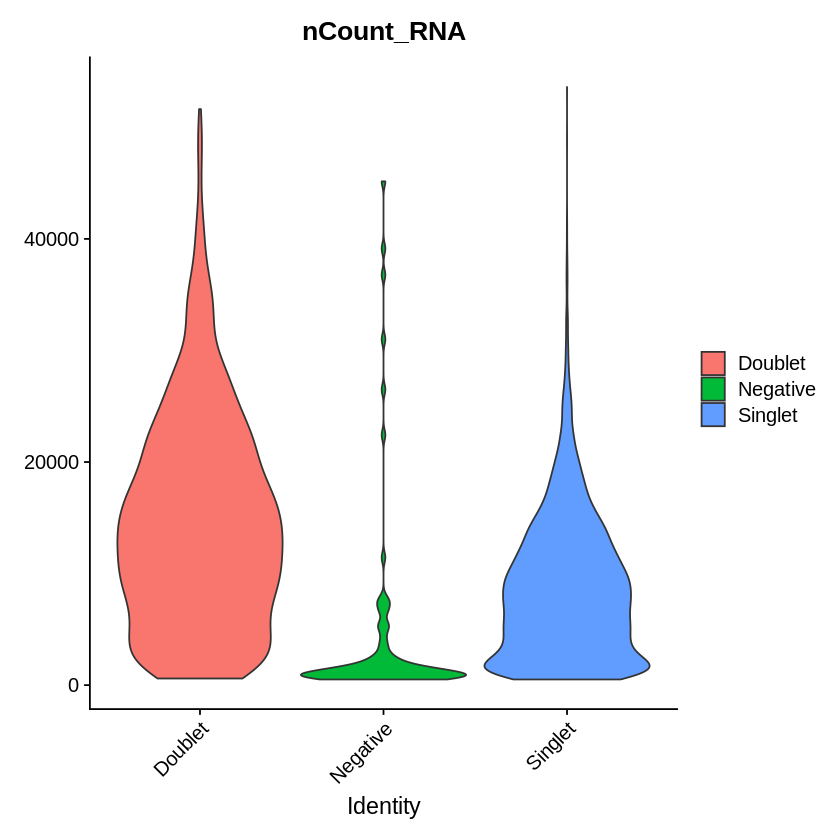

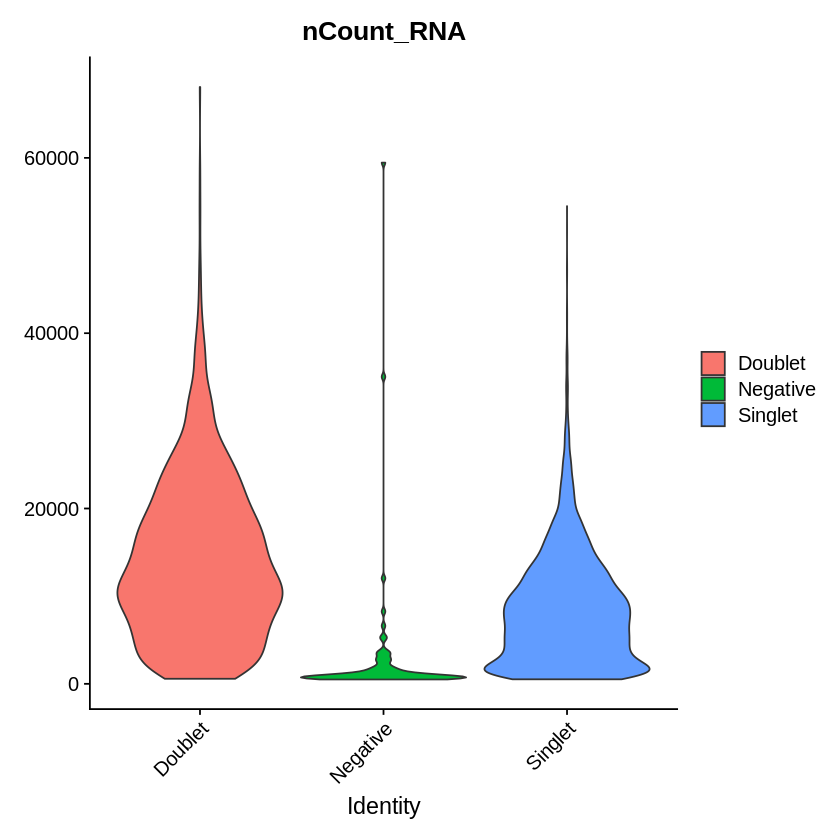

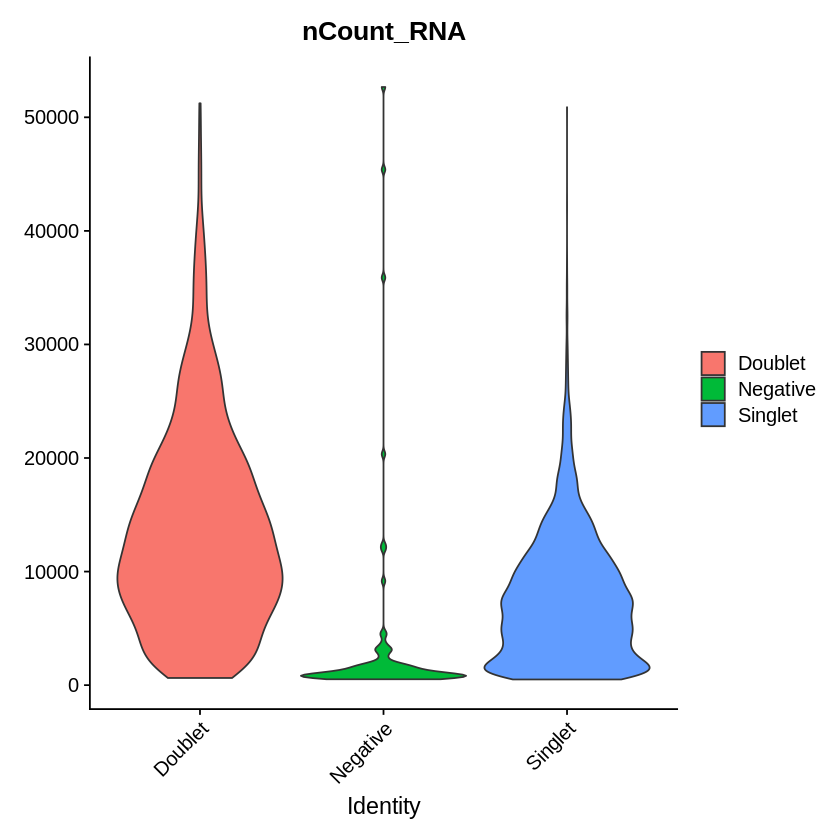

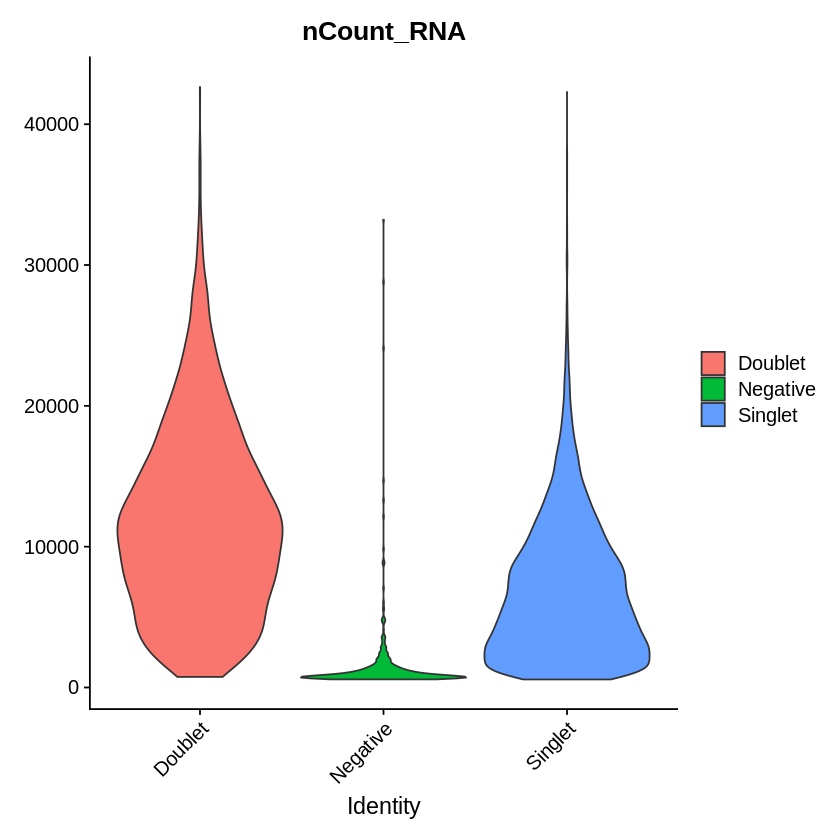

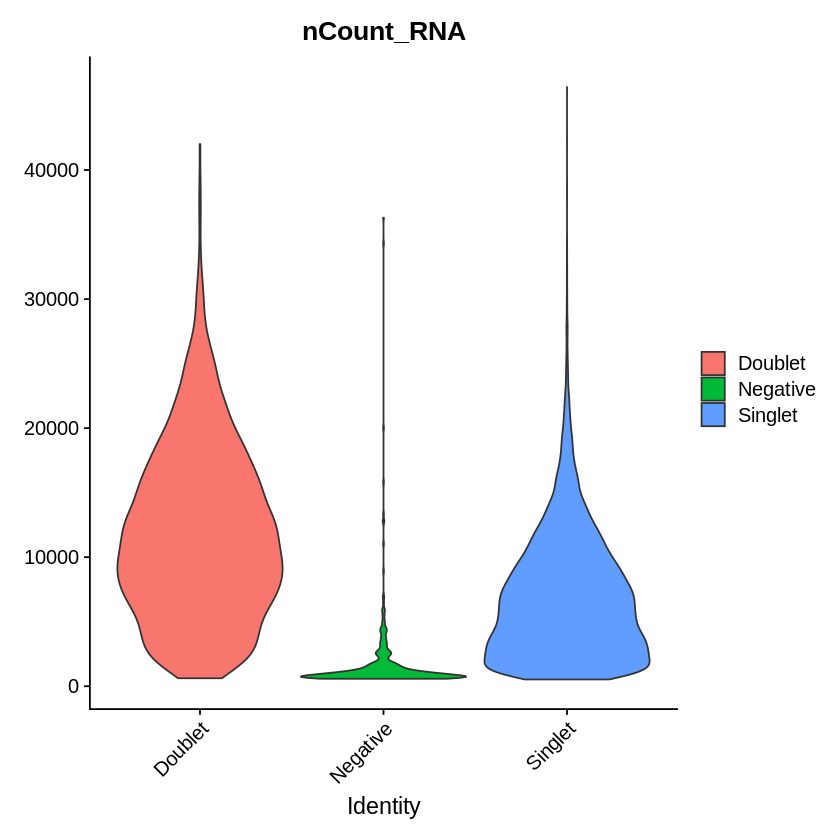

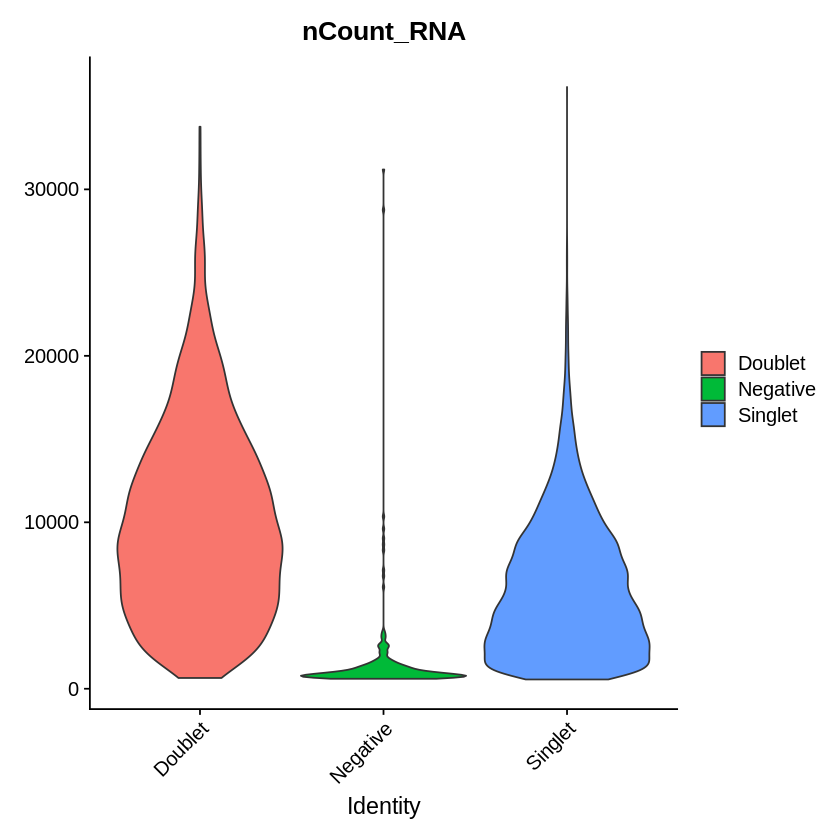

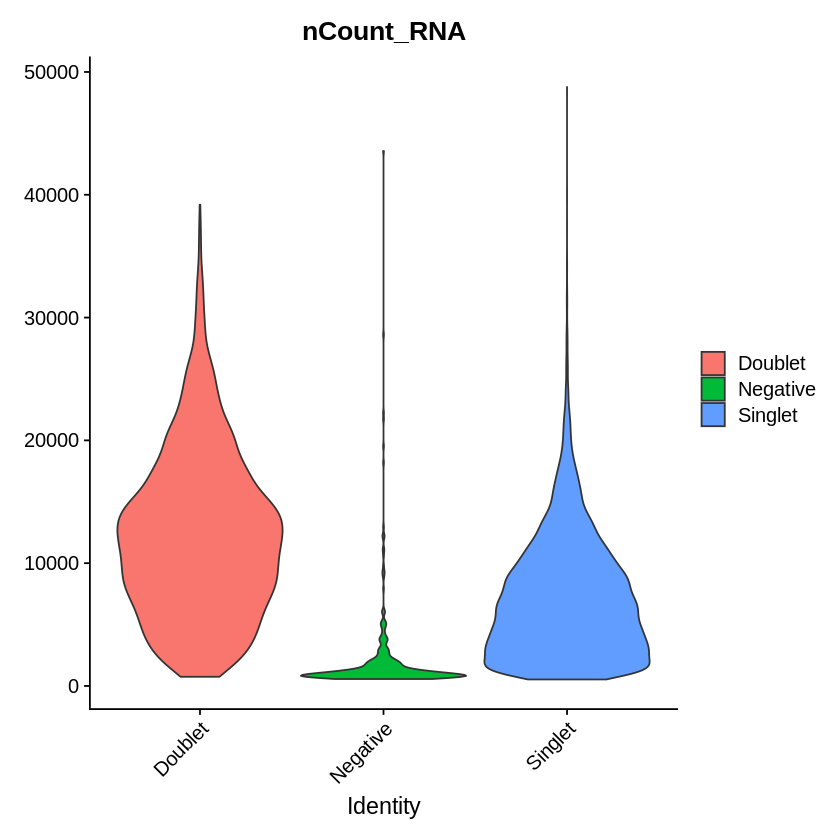

In [3]:
# Load necessary libraries
library(Seurat)
library(ggplot2)

# Assuming 'results' is the list of processed lanes
# Generate violin plots for each lane

# Define a function to create and display the violin plot for each lane
plot_violin <- function(lane_result) {
  VlnPlot(lane_result$lane, features = "nCount_RNA", group.by = "HTO_classification.global", pt.size = 0)
}

# Apply the function to each lane's result
violin_plots <- lapply(results, plot_violin)

# Display the plots in a Jupyter notebook
for (i in 1:length(violin_plots)) {
  print(violin_plots[[i]])
}

In [15]:
# Write out each lane’s metadata as a CSV
for (lane_number in seq_along(results)) {
  lane_obj   <- results[[lane_number]]$lane
  meta_data  <- lane_obj@meta.data
  out_path   <- paste0("/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/hashtag_metadata/lane",
                       lane_number, "_metadata.csv")
  print(out_path)
  write.csv(meta_data, file = out_path, quote = FALSE)
}

[1] "/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/hashtag_metadata/lane1_metadata.csv"
[1] "/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/hashtag_metadata/lane2_metadata.csv"
[1] "/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/hashtag_metadata/lane3_metadata.csv"
[1] "/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/hashtag_metadata/lane4_metadata.csv"
[1] "/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/hashtag_metadata/lane5_metadata.csv"
[1] "/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/hashtag_metadata/lane6_metadata.csv"
[1] "/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/hashtag_metadata/lane7_metadata.csv"
[1] "/Genomics/pritykinlab/dillon/perturbseq/data/gene10/preprocessing/hashtag_metadata/lane8_metadata.csv"
